| Column            | Description                                  |
| ----------------- | -------------------------------------------- |
| Posted On         | تاريخ نشر إعلان الإيجار                      |
| BHK               | عدد غرف النوم والصالة والمطبخ                |
| Rent              | قيمة الإيجار — Target                        |
| Size              | مساحة العقار، غالبًا بالقدم المربع           |
| Floor             | الطابق الذي يقع فيه العقار                   |
| Area Type         | نوع المساحة المستخدمة في وصف العقار          |
| Area Locality     | المنطقة أو الحي الذي يقع فيه العقار          |
| City              | المدينة التي يقع فيها العقار                 |
| Furnishing Status | حالة الأثاث: مفروش أو نصف مفروش أو غير مفروش |
| Tenant Preferred  | نوع المستأجر المفضل لدى المالك               |
| Bathroom          | عدد الحمامات                                 |
| Point of Contact  | جهة التواصل بخصوص الإعلان                    |


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df=pd.read_csv(r'/content/House_Rent_Dataset.csv')

In [37]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

In [38]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [40]:
df.shape

(4746, 12)

In [41]:
df.drop(columns=['Posted On'],axis=1, inplace=True)

In [42]:
print("Number of duplicate rows : ",df.duplicated().sum())

Number of duplicate rows :  8


In [43]:
df.drop_duplicates(inplace=True)

df.reset_index(drop=True,inplace=True)

In [44]:
df.isnull().sum().sort_values(ascending = False).head(8)

,0
Size,8
Area Type,7
Rent,5
Bathroom,4
BHK,0
Area Locality,0
Floor,0
City,0


In [45]:
df.dropna(subset=['Rent'], inplace=True)

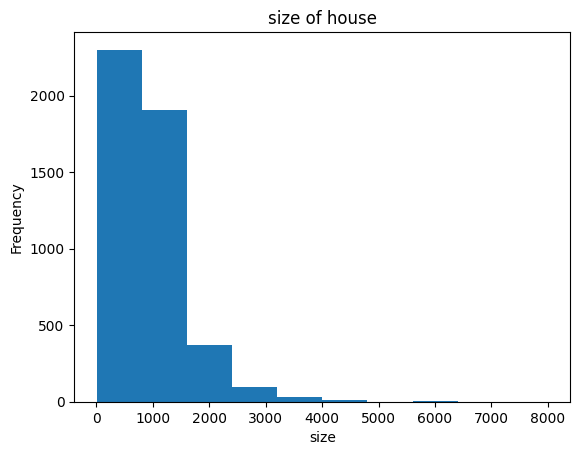

In [46]:
plt.hist(df['Size'])
plt.title('size of house')
plt.xlabel('size')
plt.ylabel('Frequency')
plt.show()

In [47]:
df['Size'].skew()

np.float64(2.3023041515597296)

In [48]:
from sklearn.impute import SimpleImputer

imputer=SimpleImputer(missing_values=np.nan,strategy='median')

imputer.fit(df[['Size']])
df['Size']=imputer.transform(df[['Size']])


In [49]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
imputer.fit(df[['Area Type']])
df['Area Type'] = imputer.transform(df[['Area Type']]).ravel()

In [50]:
df['Bathroom'].skew()

np.float64(1.27537291680705)

In [51]:
imputer=SimpleImputer(missing_values=np.nan,strategy='mean')

imputer.fit(df[['Bathroom']])
df['Bathroom']=imputer.transform(df[['Bathroom']])

In [52]:
df.isnull().sum().sum()

np.int64(0)

In [53]:
df.select_dtypes(include=['object']).columns

Index(['Floor', 'Area Type', 'Area Locality', 'City', 'Furnishing Status',
       'Tenant Preferred', 'Point of Contact'],
      dtype='object')

In [54]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of column {col} is : ',df[col].nunique())
    print(f'number of column {col} is : ',df[col].unique())

number of column Floor is :  480
number of column Floor is :  ['Ground out of 2' '1 out of 3' '1 out of 2' 'Ground out of 1'
 'Ground out of 4' '1 out of 4' '1 out of 1' 'Ground out of 3'
 '2 out of 3' '4 out of 5' '2 out of 2' '2 out of 5' '4 out of 14'
 '3 out of 3' '5 out of 5' '4 out of 4' '7 out of 8' '2 out of 4'
 '3 out of 4' '1 out of 5' '8 out of 5' 'Ground out of 6' '2 out of 1'
 'Upper Basement out of 4' 'Ground out of 5' '3 out of 5' '11 out of 19'
 '5 out of 10' '11 out of 14' 'Lower Basement out of 2' '2 out of 7'
 '4 out of 10' '7 out of 10' '2 out of 13' '6 out of 7' '4 out of 7'
 '14 out of 14' '43 out of 78' '2 out of 8' '13 out of 18' '5 out of 12'
 '18 out of 24' '3 out of 7' '17 out of 31' '11 out of 21' '7 out of 19'
 '14 out of 23' '9 out of 20' 'Upper Basement out of 9' '19 out of 24'
 '3 out of 21' '1 out of 22' '8 out of 8' '6 out of 12' '4 out of 58'
 'Upper Basement out of 16' '60 out of 66' '34 out of 48' '5 out of 8'
 '5 out of 14' '14 out of 40' '5 out of

In [55]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

categorical_cols = ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.0,Ground out of 2,2,Bandel,4,2,1,2.0,2
1,2,20000.0,850.0,1 out of 3,2,"Phool Bagan, Kankurgachi",4,1,1,1.0,2
2,2,17000.0,1000.0,1 out of 3,2,Salt Lake City Sector 2,4,1,1,1.0,2
3,2,10000.0,850.0,1 out of 2,2,Dumdum Park,4,2,1,1.0,2
4,2,7500.0,850.0,1 out of 2,1,South Dum Dum,4,2,0,1.0,2


In [56]:
from scipy.stats import zscore

def remove_outliers_zscore(data, column_name="value", threshold=3.0):
    z_scores = zscore(data[column_name])
    return data[np.abs(z_scores) < threshold]
cleaned_df = remove_outliers_zscore(df, column_name="Rent")

print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)

Original shape: (4733, 11)
Cleaned shape: (4667, 11)


In [57]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.0,Ground out of 2,2,Bandel,4,2,1,2.0,2
1,2,20000.0,850.0,1 out of 3,2,"Phool Bagan, Kankurgachi",4,1,1,1.0,2
2,2,17000.0,1000.0,1 out of 3,2,Salt Lake City Sector 2,4,1,1,1.0,2
3,2,10000.0,850.0,1 out of 2,2,Dumdum Park,4,2,1,1.0,2
4,2,7500.0,850.0,1 out of 2,1,South Dum Dum,4,2,0,1.0,2


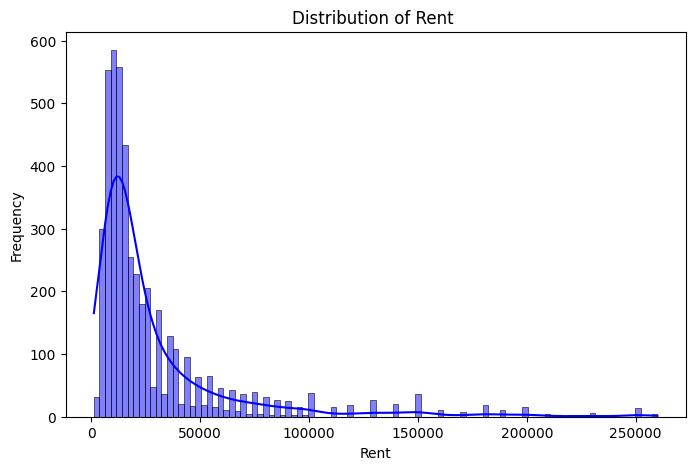

In [58]:
plt.figure(figsize=(8, 5))
sns.histplot(cleaned_df['Rent'], kde=True, color='blue')
plt.title('Distribution of Rent ')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

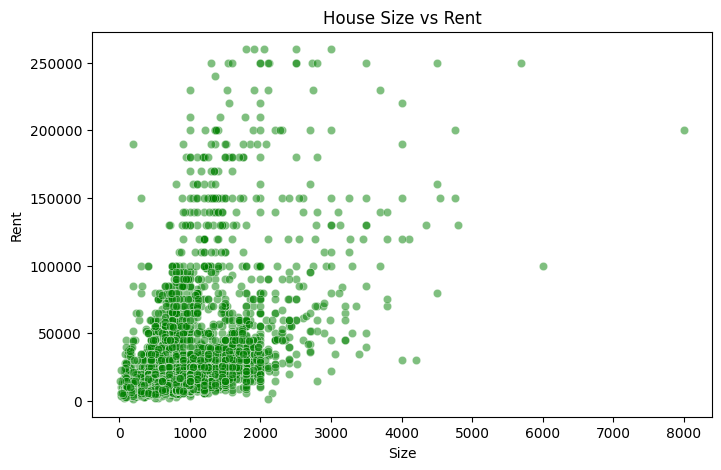

In [59]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Size', y='Rent', data=cleaned_df, alpha=0.5, color='green')
plt.title('House Size vs Rent')
plt.xlabel('Size')
plt.ylabel('Rent')
plt.show()

/tmp/ipykernel_359/110861890.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='City', y='Rent', data=cleaned_df, estimator=np.mean, palette='muted')


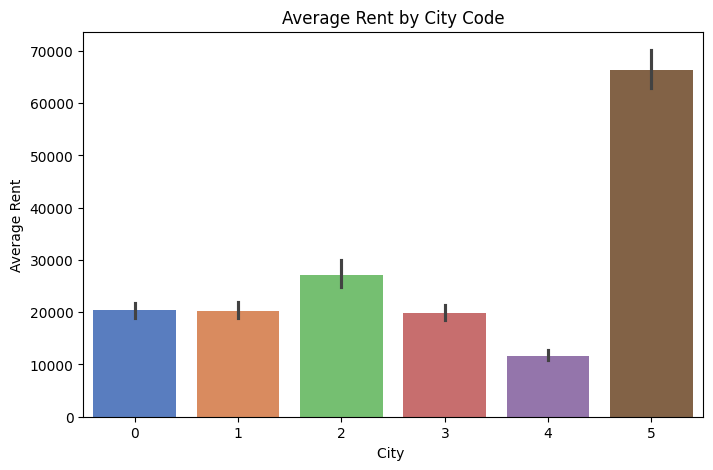

In [60]:

plt.figure(figsize=(8, 5))
sns.barplot(x='City', y='Rent', data=cleaned_df, estimator=np.mean, palette='muted')
plt.title('Average Rent by City Code')
plt.xlabel('City ')
plt.ylabel('Average Rent')
plt.show()

/tmp/ipykernel_359/3197138016.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Furnishing Status', data=cleaned_df, palette='Set2')


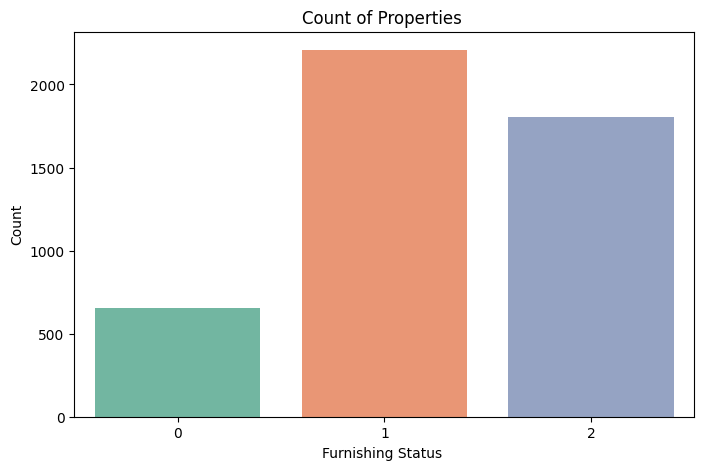

In [61]:

plt.figure(figsize=(8, 5))
sns.countplot(x='Furnishing Status', data=cleaned_df, palette='Set2')
plt.title('Count of Properties ')
plt.xlabel('Furnishing Status ')
plt.ylabel('Count')
plt.show()

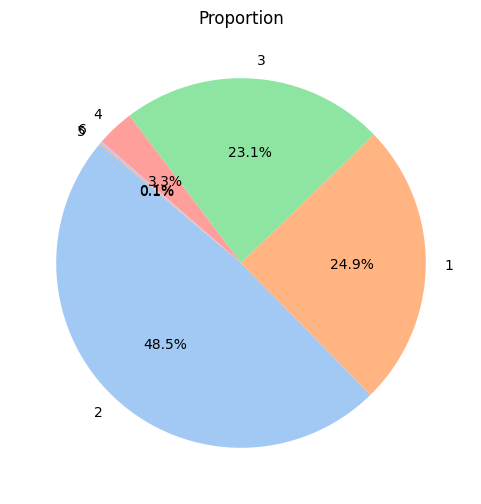

In [62]:

plt.figure(figsize=(6, 6))
bhk_counts = cleaned_df['BHK'].value_counts()
plt.pie(bhk_counts, labels=bhk_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proportion')
plt.show()

In [63]:
numeric_features = [
    'BHK',
    'Size',
    'Bathroom'
]

categorical_features = [
    'Floor',
    'Area Type',
    'Area Locality',
    'City',
    'Furnishing Status',
    'Tenant Preferred',
    'Point of Contact'
]

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [65]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [66]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

In [67]:
X=cleaned_df.drop(columns=['Rent'])
y=cleaned_df['Rent']

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [69]:
X = cleaned_df.drop(columns=['Rent'])
y = cleaned_df['Rent']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (3733, 10)
X_test shape: (934, 10)


In [70]:
from sklearn.ensemble import RandomForestRegressor

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [71]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BHK', 'Size', 'Bathroom']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Floor', 'Area Type',
                                                   'Area Locality', 'City',
                                                   'Furnishing Status',
                                                   'Tenant Preferred',
                                                   'Point of Contact'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [72]:
y_pred = model_pipeline.predict(X_test)

In [73]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import numpy as np

# Re-initialize the pipeline using our existing preprocessor
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit the pipeline
model_pipeline.fit(X_train, y_train)

# Generate predictions
y_pred = model_pipeline.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R-squared (R²) Score: {r2:.4f}")

Mean Absolute Error (MAE): 8,347.91
Mean Squared Error (MSE): 328,575,216.34
Root Mean Squared Error (RMSE): 18,126.64
R-squared (R²) Score: 0.7634


In [76]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 49.7 MB/s  0:00:02


In [77]:
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [78]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [79]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [80]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

  0%|          | 0/15 [00:00<?, ?it/s]


ValueError: could not convert string to float: '3 out of 5'

  0%|          | 0/15 [00:00<?, ?it/s]

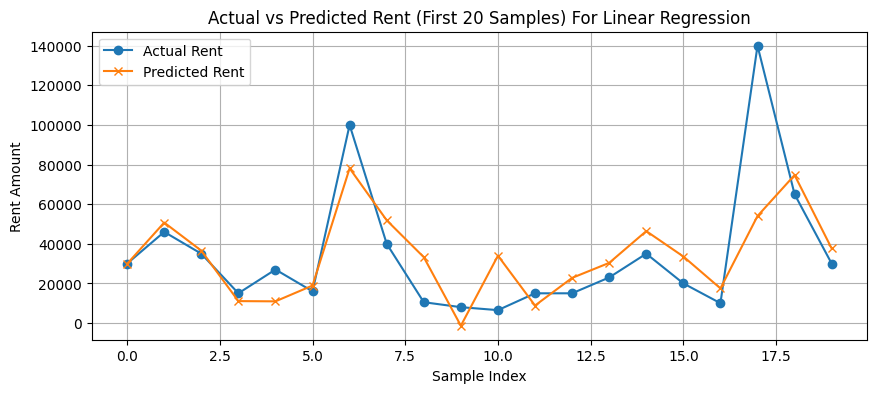

  7%|▋         | 1/15 [00:08<01:57,  8.37s/it]

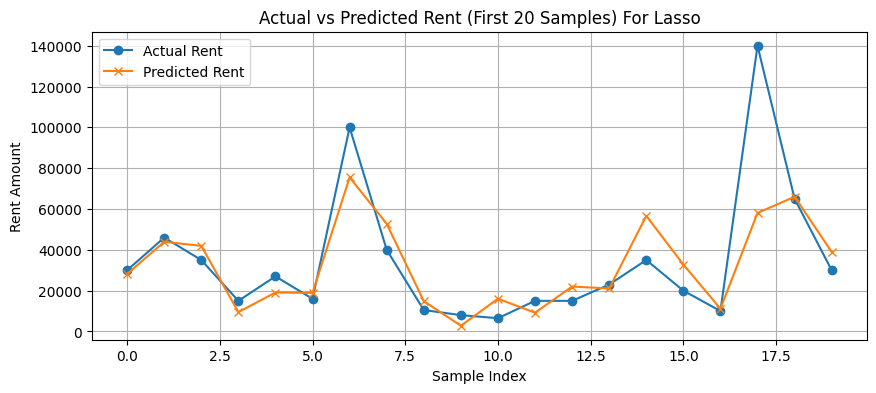

 13%|█▎        | 2/15 [00:09<00:54,  4.20s/it]

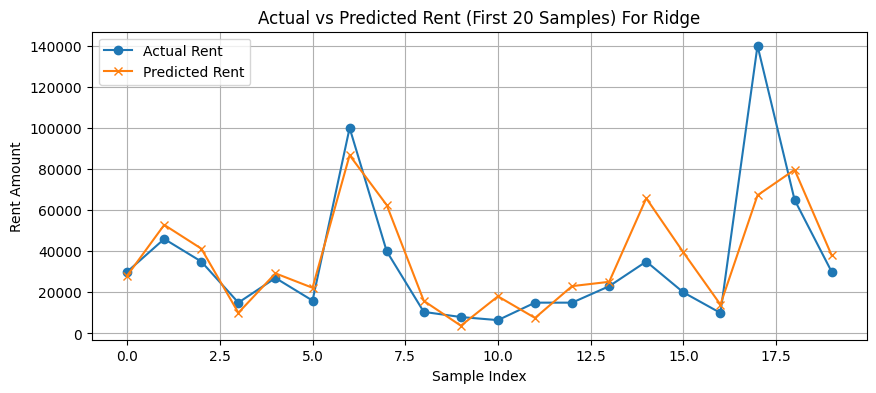

 20%|██        | 3/15 [00:10<00:33,  2.81s/it]

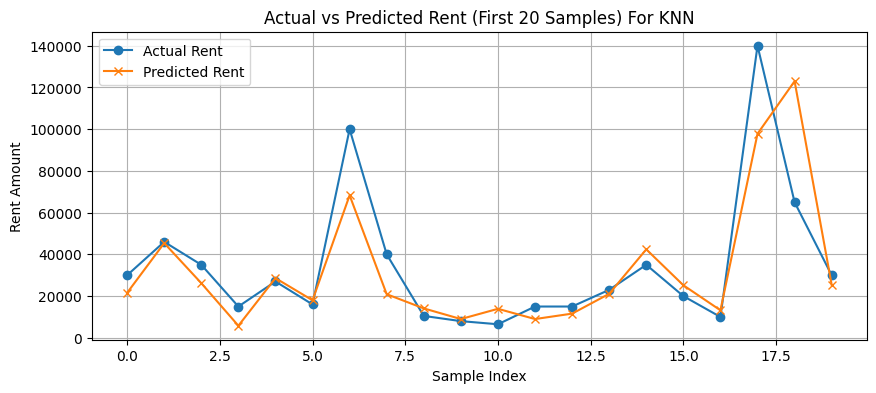

 27%|██▋       | 4/15 [00:50<03:13, 17.56s/it]

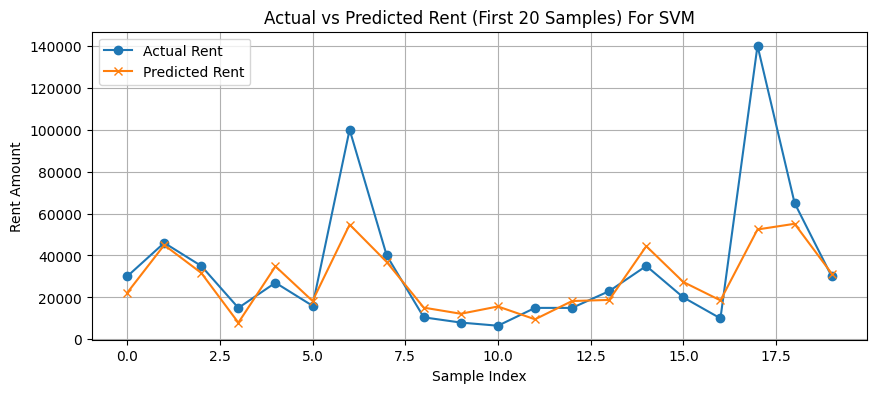

 33%|███▎      | 5/15 [01:25<03:57, 23.75s/it]

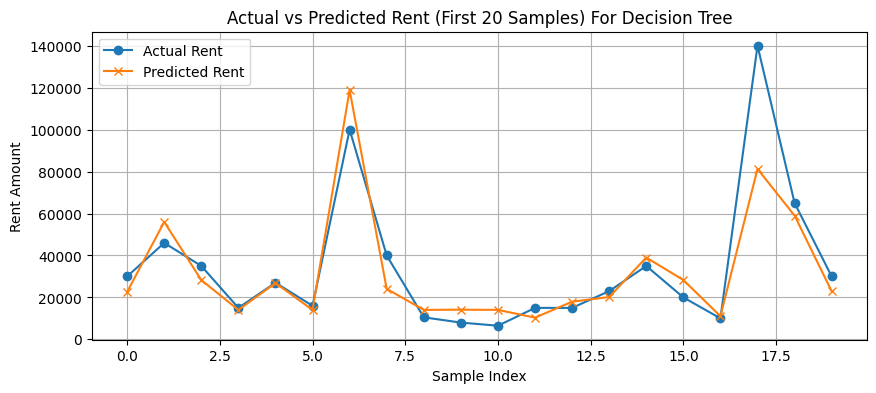

 40%|████      | 6/15 [01:26<02:22, 15.85s/it]

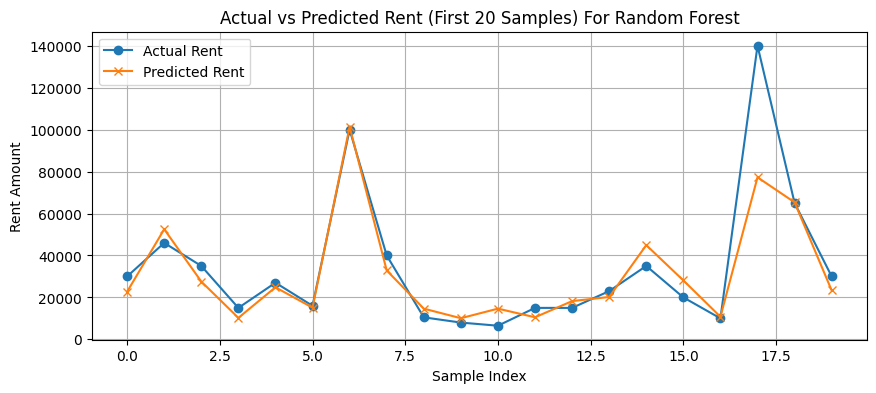

 47%|████▋     | 7/15 [01:32<01:41, 12.72s/it]

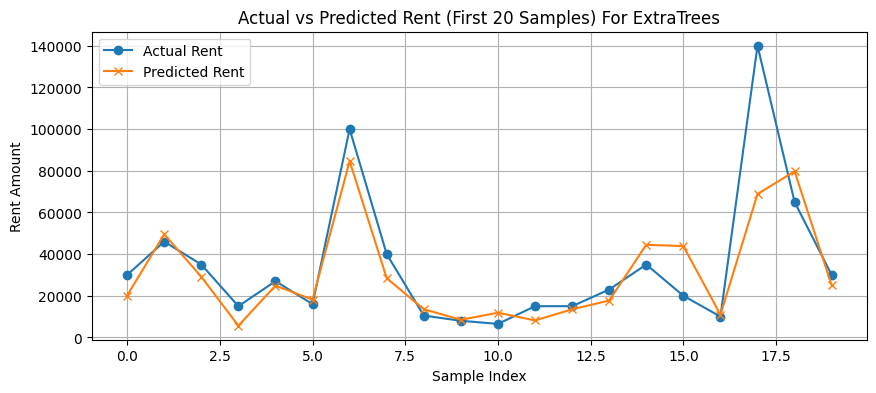

 53%|█████▎    | 8/15 [02:11<02:27, 21.02s/it]

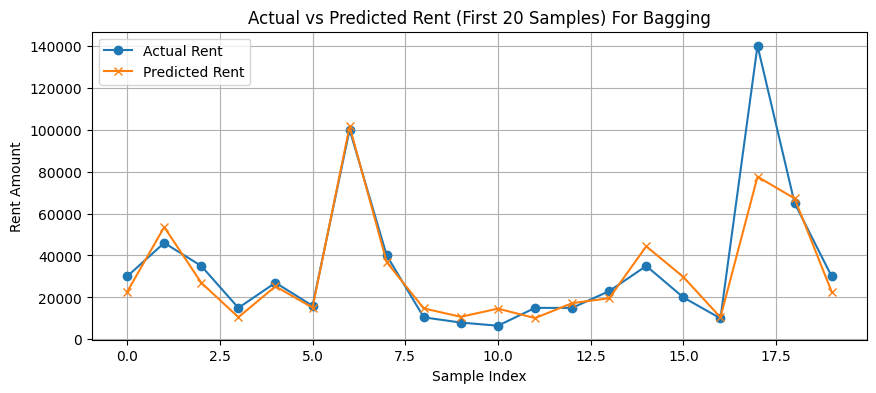

 60%|██████    | 9/15 [02:20<01:43, 17.29s/it]

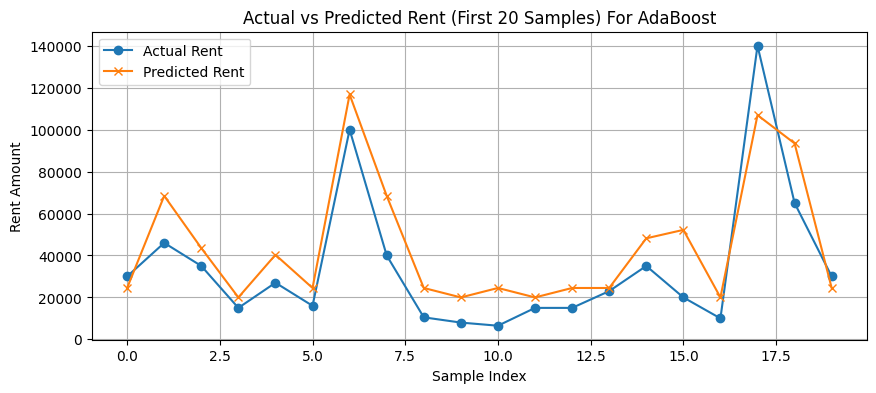

 67%|██████▋   | 10/15 [02:23<01:03, 12.79s/it]

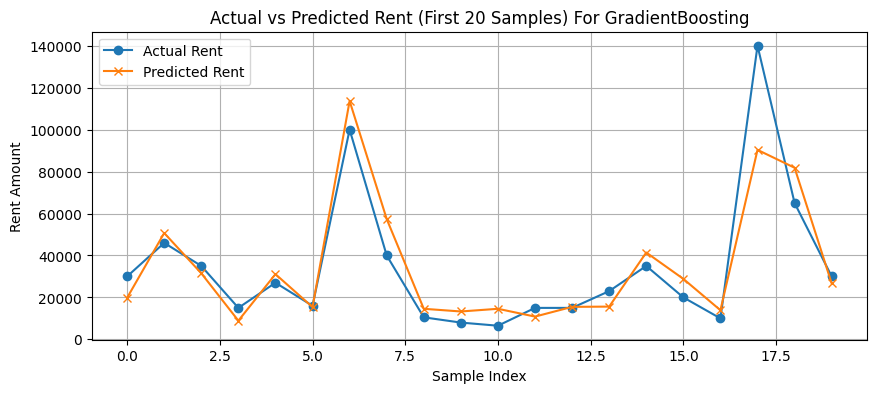

 73%|███████▎  | 11/15 [02:45<01:02, 15.59s/it]

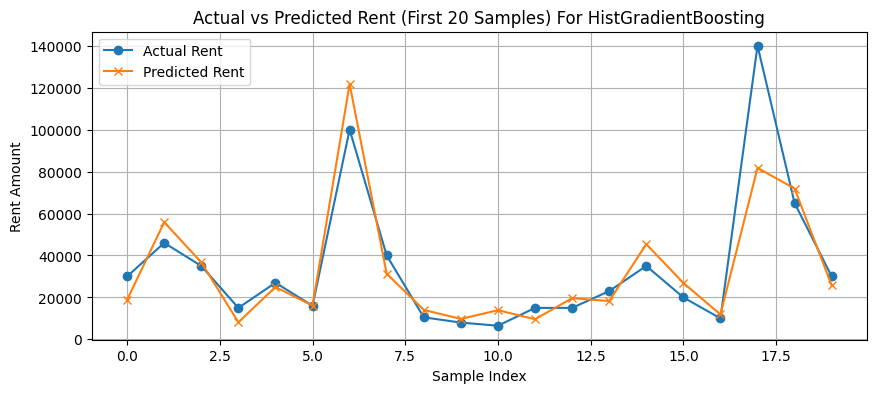

 80%|████████  | 12/15 [02:57<00:44, 14.74s/it]

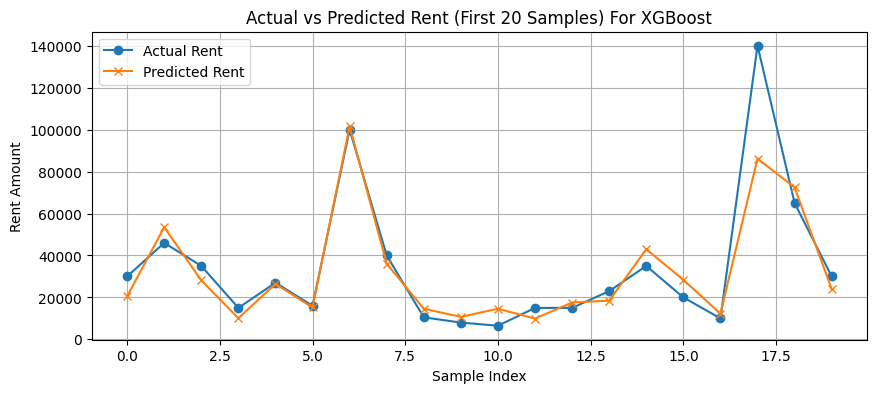

 87%|████████▋ | 13/15 [03:00<00:22, 11.18s/it]

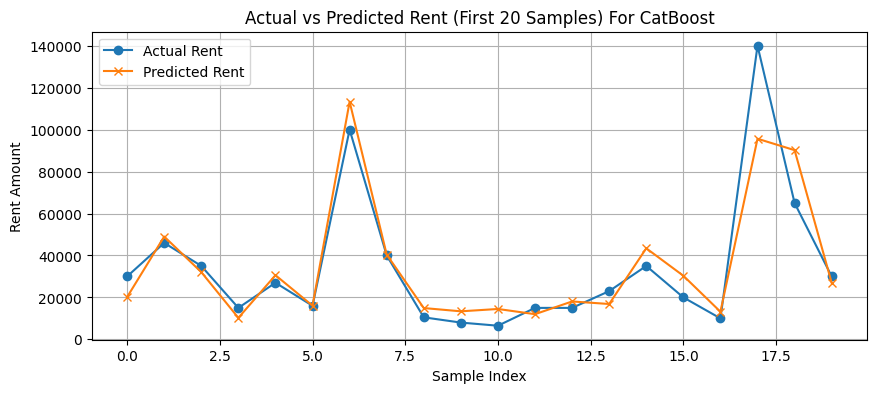

 93%|█████████▎| 14/15 [03:02<00:08,  8.21s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001619 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 343
[LightGBM] [Info] Number of data points in the train set: 3733, number of used features: 43
[LightGBM] [Info] Start training from score 29127.290651


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


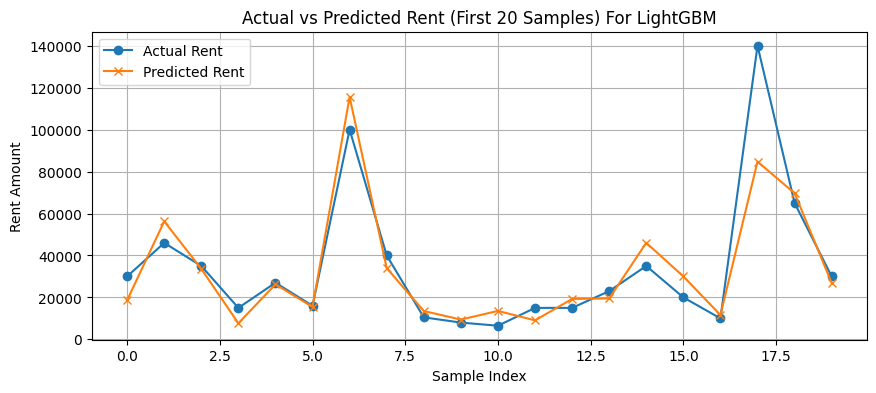

100%|██████████| 15/15 [03:02<00:00, 12.18s/it]


In [81]:
from sklearn.pipeline import Pipeline

errors = {}

# Loop through each model, wrap it in a pipeline with our preprocessor, and fit it
for model_name, model in tqdm(models.items()):
    # Wrap current model in the pipeline with preprocessor
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Fit the pipeline
    pipeline.fit(X_train, y_train)

    # Calculate metrics using our regression_metrics function passing the pipeline
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(pipeline, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(pipeline, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = pipeline.predict(X_test[:20])

    plt.figure(figsize=(10, 4))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title(f'Actual vs Predicted Rent (First 20 Samples) For {model_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

In [83]:
from sklearn.pipeline import Pipeline

# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors
voting_base1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

voting_base2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
voting_base3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Wrap each VotingRegressor inside a Pipeline with the preprocessor
model1 = Pipeline(steps=[('preprocessor', preprocessor), ('model', voting_base1)])
model2 = Pipeline(steps=[('preprocessor', preprocessor), ('model', voting_base2)])
model3 = Pipeline(steps=[('preprocessor', preprocessor), ('model', voting_base3)])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }

In [84]:
# Convert the errors dictionary to a Pandas DataFrame
all_metrics_df = pd.DataFrame(errors).T

# Sort the models by Test R2 score in descending order
all_metrics_df = all_metrics_df.sort_values(by="R2 Test", ascending=False)

# Display the structured metrics table with background gradients
print("--- All Models & Ensembles Sorted by Test R2 Score ---")
display(all_metrics_df.style.background_gradient(cmap='Greens', subset=['R2 Train', 'R2 Test']))

--- All Models & Ensembles Sorted by Test R2 Score ---


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,6336.031760,8542.107165,97921481.663973,302629112.712566,9895.528367,17396.238464,0.925335,0.782055
GradientBoosting,7923.374107,8968.308780,177672917.370394,307411331.816548,13329.400488,17533.149512,0.864525,0.778611
CatBoost,8114.455488,8858.966900,210357094.851374,317622864.897286,14503.692456,17821.977020,0.839604,0.771257
Random Forest,6123.035531,8573.264600,95910130.947352,325302522.180054,9793.371786,18036.144881,0.926869,0.765727
Bagging,6146.025935,8610.367749,96723672.262370,335763626.878307,9834.819381,18323.854040,0.926249,0.758193
Voting,1923.633096,8859.384827,13995734.795029,340757105.770690,3741.087381,18459.607411,0.989328,0.754597
Simple Voting,1923.633096,8859.384827,13995734.795029,340757105.770690,3741.087381,18459.607411,0.989328,0.754597
ExtraTrees,3.822663,8608.421413,3610.192874,345583974.958391,60.084881,18589.889052,0.999997,0.751121
LightGBM,7011.300244,8944.543560,169881482.258964,346209187.181320,13033.859070,18606.697374,0.870466,0.750670
HistGradientBoosting,7107.977543,8941.669952,175963675.671966,347043210.355736,13265.130066,18629.095801,0.865829,0.750070


In [86]:
from sklearn.pipeline import Pipeline

# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_base = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

# Wrap StackingRegressor in a Pipeline with our preprocessor
stacking_regressor = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', stacking_base)
])

# Fit the pipeline
stacking_regressor.fit(X_train, y_train)

# Calculate metrics using the pipeline
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)

errors["Stacking"] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [ ]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

In [ ]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()